# 03 — Análise exploratória das bases

Oito gráficos comentados, organizados por fonte. Os cinco primeiros descrevem **cenários simulados** pelo INCT SiMAI; os três últimos descrevem **medições observadas** pela ANA. As escalas e os resultados não são usados para validar uma base com a outra.

**Fontes:** `data.json` do INCT SiMAI fornecido no projeto; [Hidro‑Telemetria da ANA](https://www.snirh.gov.br/hidrotelemetria/) (estação 87450020, coleta registrada em `dados/originais/ana_metadados_coleta.csv`).

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
FIG = ROOT / 'resultados' / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
inct = pd.read_csv(ROOT / 'dados/processados/inct_simai_limpo.csv')
summary = pd.read_csv(ROOT / 'dados/processados/inct_resumo_por_nivel.csv')
ana = pd.read_csv(ROOT / 'dados/processados/ana_guaiba_2024_limpo.csv', parse_dates=['data_hora'])
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
fmt = FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.'))
def save(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=160, bbox_inches='tight'); plt.show()

## INCT 1/5 — Pessoas afetadas por nível
A curva mostra como a estimativa da cidade inteira evolui nos 71 cenários. O pico citado no enunciado, 5,35 m, fica entre os cenários 5,3 e 5,4 m; não há cenário calculado exatamente em 5,35 m.

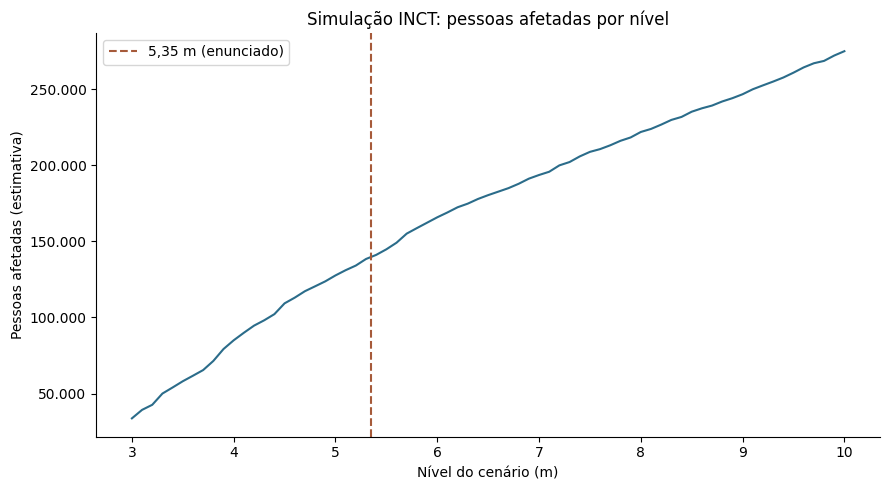

In [2]:
fig, ax = plt.subplots()
ax.plot(summary.nivel_m, summary.pessoas_afetadas, color='#2b6c8a')
ax.axvline(5.35, color='#a65a3a', linestyle='--', label='5,35 m (enunciado)')
ax.set(xlabel='Nível do cenário (m)', ylabel='Pessoas afetadas (estimativa)', title='Simulação INCT: pessoas afetadas por nível')
ax.yaxis.set_major_formatter(fmt); ax.legend(); save('01_inct_pessoas_por_nivel.png')

## INCT 2/5 — Prédios afetados por nível
A contagem após limpeza é não decrescente, como esperado para cenários acumulativos de inundação.

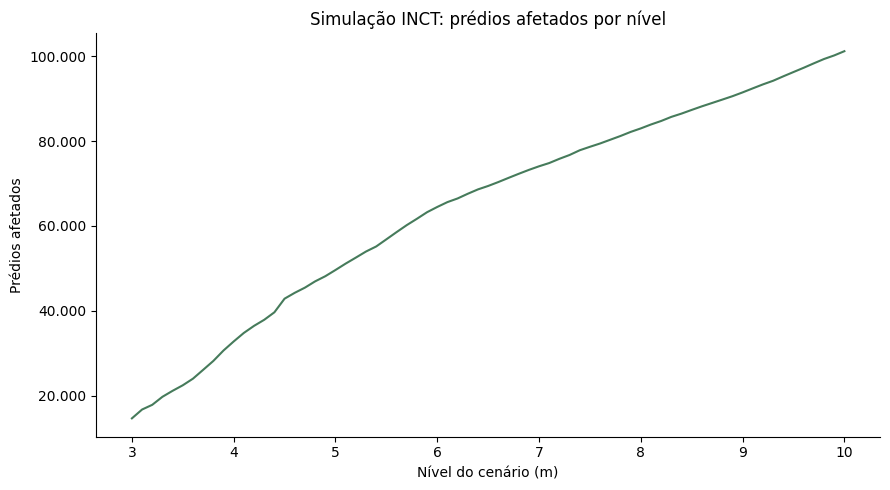

In [3]:
fig, ax = plt.subplots()
ax.plot(summary.nivel_m, summary.predios_afetados, color='#467b5b')
ax.set(xlabel='Nível do cenário (m)', ylabel='Prédios afetados', title='Simulação INCT: prédios afetados por nível')
ax.yaxis.set_major_formatter(fmt); save('02_inct_predios_por_nivel.png')

## INCT 3/5 — Bairros atingidos por nível
Um bairro conta como atingido quando há pelo menos um prédio afetado.

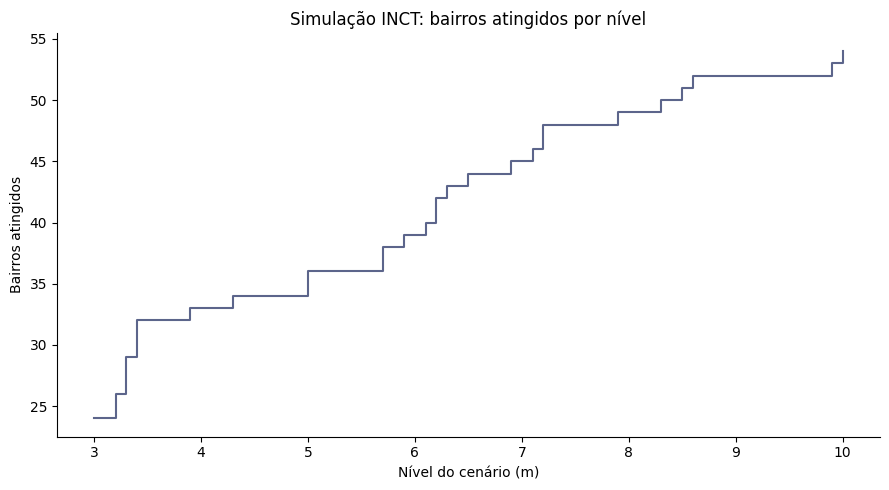

In [4]:
fig, ax = plt.subplots()
ax.step(summary.nivel_m, summary.bairros_atingidos, where='post', color='#5c658b')
ax.set(xlabel='Nível do cenário (m)', ylabel='Bairros atingidos', title='Simulação INCT: bairros atingidos por nível')
save('03_inct_bairros_por_nivel.png')

## INCT 4/5 — Ranking no cenário de 5,3 m
O ranking usa a população afetada estimada, não pessoas observadas em 2024.

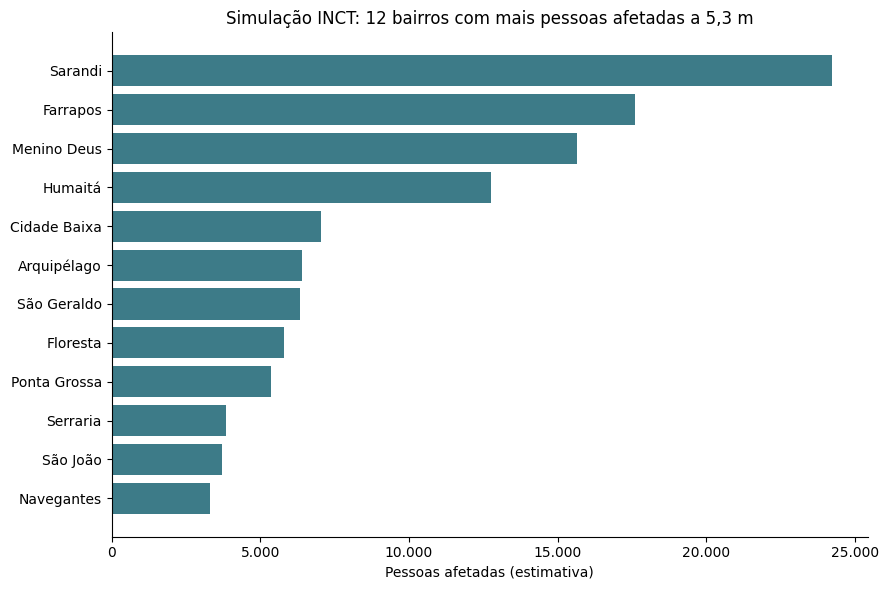

In [5]:
snap = inct[inct.nivel_m.eq(5.3)].nlargest(12, 'affected_population').sort_values('affected_population')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(snap.bairro, snap.affected_population, color='#3d7b88')
ax.set(xlabel='Pessoas afetadas (estimativa)', title='Simulação INCT: 12 bairros com mais pessoas afetadas a 5,3 m')
ax.xaxis.set_major_formatter(fmt); save('04_inct_ranking_53.png')

## INCT 5/5 — Distribuição da fração de prédios afetados
O percentual exato evita esconder pequenas diferenças causadas pelo arredondamento para cima usado no arquivo original.

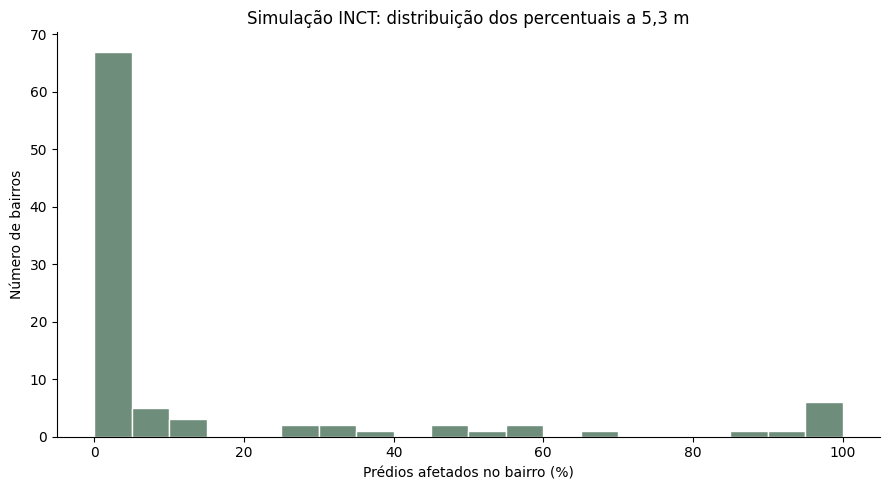

In [6]:
fig, ax = plt.subplots()
ax.hist(inct.loc[inct.nivel_m.eq(5.3), 'percentage_exact'], bins=np.arange(0, 105, 5), color='#6f8d7b', edgecolor='white')
ax.set(xlabel='Prédios afetados no bairro (%)', ylabel='Número de bairros', title='Simulação INCT: distribuição dos percentuais a 5,3 m')
save('05_inct_distribuicao_percentual_53.png')

## ANA 1/3 — Série temporal observada
A linha mostra somente as medições disponíveis. Lacunas são mantidas como lacunas no CSV processado; o gráfico não deve ser lido como previsão.

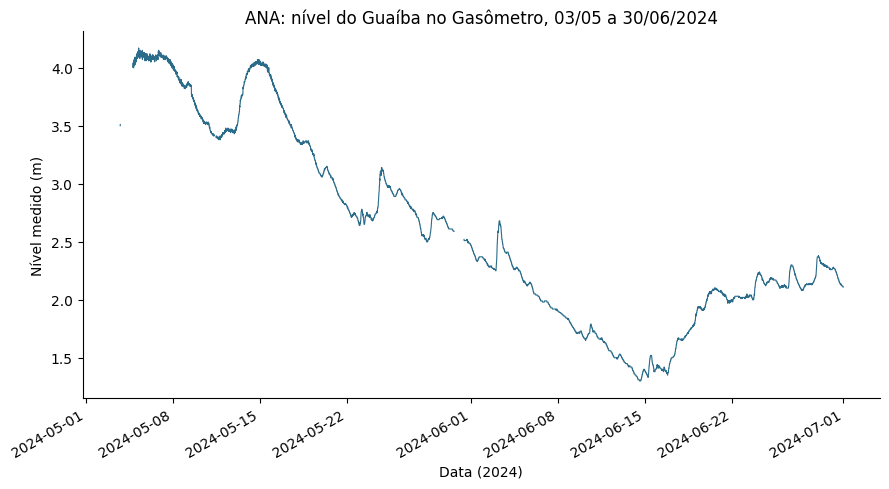

In [7]:
fig, ax = plt.subplots()
ax.plot(ana.data_hora, ana.nivel_m, linewidth=0.8, color='#2b6c8a')
ax.set(xlabel='Data (2024)', ylabel='Nível medido (m)', title='ANA: nível do Guaíba no Gasômetro, 03/05 a 30/06/2024')
fig.autofmt_xdate(); save('06_ana_serie_temporal.png')

## ANA 2/3 — Faixa diária de níveis
Mínimos e máximos diários resumem a variação observada sem substituir as medições originais.

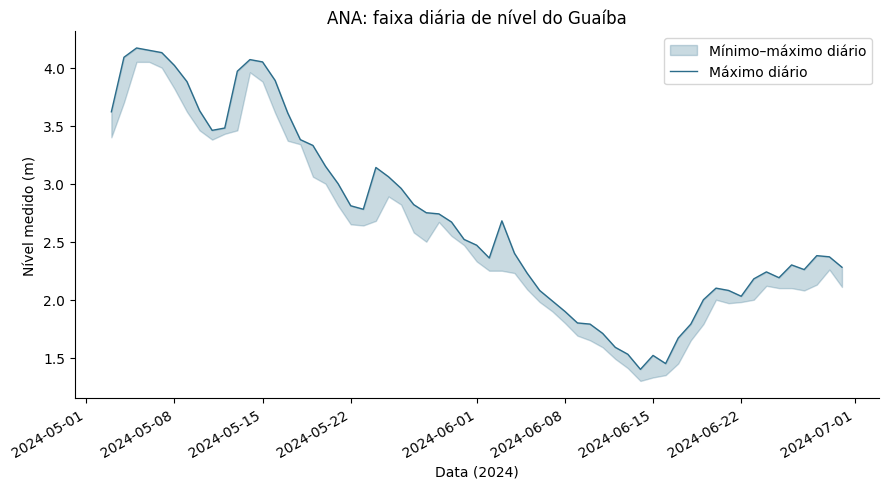

In [8]:
daily = ana.set_index('data_hora').nivel_m.resample('D').agg(['min','max','count'])
fig, ax = plt.subplots()
ax.fill_between(daily.index, daily['min'], daily['max'], alpha=0.25, color='#2b6c8a', label='Mínimo–máximo diário')
ax.plot(daily.index, daily['max'], color='#2b6c8a', linewidth=1, label='Máximo diário')
ax.set(xlabel='Data (2024)', ylabel='Nível medido (m)', title='ANA: faixa diária de nível do Guaíba')
ax.legend(); fig.autofmt_xdate(); save('07_ana_faixa_diaria.png')

## ANA 3/3 — Completude diária
A contagem de medições com nível mostra os dias com lacunas. Em intervalos de 15 minutos, 96 medições representariam um dia completo; isso é apenas referência de completude, não garantia de periodicidade em todos os registros.

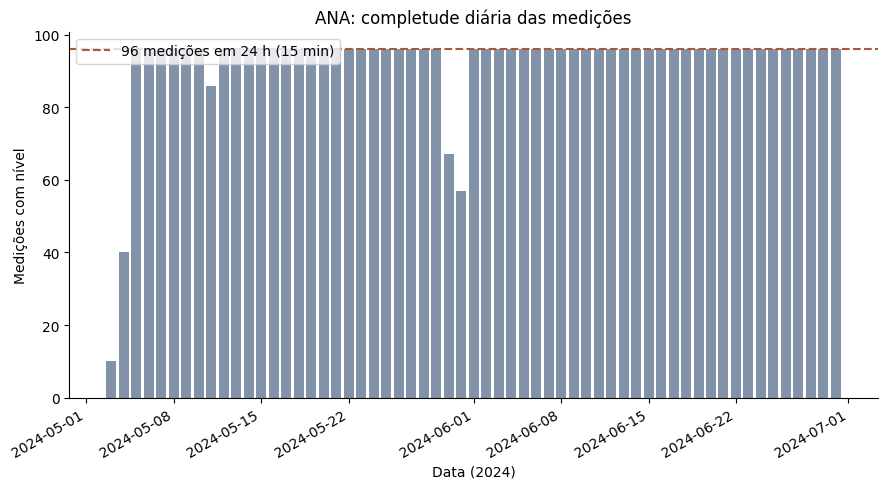

In [9]:
fig, ax = plt.subplots()
ax.bar(daily.index, daily['count'], width=0.8, color='#8292a8')
ax.axhline(96, color='#a65a3a', linestyle='--', label='96 medições em 24 h (15 min)')
ax.set(xlabel='Data (2024)', ylabel='Medições com nível', title='ANA: completude diária das medições')
ax.legend(); fig.autofmt_xdate(); save('08_ana_completude_diaria.png')

## Síntese para o projeto

- **Tela 1:** a base limpa do INCT permite preencher indicadores, curva e ranking por cenário.
- **Tela 2:** a série observada da ANA permite apresentar a evolução do nível e a qualidade temporal das medições em 2024.
- O resultado do INCT é uma **simulação de exposição**; o resultado da ANA é uma **medição do nível**. As análises aqui permanecem separadas.
- Toda correção de dados está em `dados/processados/auditoria_inct.csv` ou `auditoria_ana.csv`.